# **Failure Analysis — which attacks slip past the guards, and why?**

The "guards" are the organizers' fixed detectors, **ECOD** and **IForest** (10 seeds × 500 trees). They train on our synthetic CSV and then score unseen rows. Here we copy them locally, the same way `pseudo kaggle.ipynb` does, and look at the attacks they **miss**.

Each missed attack is sorted into one of three buckets, based on how close it sits to real normal rows and to our synthetic rows:

| bucket | what it means | can a better synthetic dataset fix it? |
|---|---|---|
| **A. Looks like real normal** | The attack sits right on top of real normal traffic. | **No.** Any dataset that represents normal traffic will hide it. This is the ceiling. |
| **B. Hidden by our synthetic data** | Close to our synthetic rows but far from real normals, so our generator filled in space that real normal traffic doesn't use. | **Yes.** Stop generating there. |
| **C. Far from both** | Unusual compared with everything, yet the guards still score it low. | **Maybe.** It's a blind spot of how ECOD/IForest score, for example a combination of values where each value on its own looks normal. |

**Data (no leakage):** the synthetic file must come from `VAE.ipynb` with `clf_holdout=True`, so its filter only saw anomaly half A. The eval set is all train normals plus anomaly **half B**, the same split as `pseudo kaggle.ipynb`.

---
**Config**

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyod.models.ecod import ECOD
from pyod.models.iforest import IForest
from sklearn.metrics import average_precision_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

DATASET = "UNSW"   # "NSL" | "UNSW"
ROOT = Path("/Users/han./Desktop/CS5344")
CONFIGS = {
    "NSL": dict(path=ROOT / "data/raw/NSL-KDD_train.csv",
                cat_cols=["protocol_type", "service", "flag"],
                synth=ROOT / "data/processed/synthetic_NSL_clf0.5_holdout.csv"),
    "UNSW": dict(path=ROOT / "data/raw/UNSW-NB15_train.csv",
                 cat_cols=["proto", "service", "state"],
                 synth=ROOT / "data/processed/synthetic_UNSW_clf0.01_holdout.csv"),
}
cfg = CONFIGS[DATASET]
LABEL = "is_anomaly"
N_SEEDS = 10
MISS_QUANTILE = 0.95   # an attack is "missed" if its score is below this quantile of normal scores

df = pd.read_csv(cfg["path"])
cat_cols = cfg["cat_cols"]
feature_cols = [c for c in df.columns if c != LABEL]
num_cols = [c for c in feature_cols if c not in cat_cols]
normal_df = df[df[LABEL] == 0].reset_index(drop=True)
anom = df[df[LABEL] == 1].sample(frac=1, random_state=0)       # same split as VAE / pseudo kaggle
anom_B = anom.iloc[len(anom) // 2:].reset_index(drop=True)
eval_df = pd.concat([normal_df, anom_B], ignore_index=True)
y = eval_df[LABEL].to_numpy()
synth = pd.read_csv(cfg["synth"]).drop(columns="id")
print(f"{DATASET}: synthetic {synth.shape}, eval {len(eval_df)} rows ({y.sum()} attacks from half B)")

UNSW: synthetic (70000, 42), eval 42500 rows (7500 attacks from half B)


---
**1. Copy the guards: train on the synthetic data, score the eval rows**

In [2]:
ohe_cols = pd.get_dummies(synth[feature_cols], columns=cat_cols, dtype=float).columns
def onehot(d):
    return pd.get_dummies(d[feature_cols], columns=cat_cols, dtype=float).reindex(columns=ohe_cols, fill_value=0.0)

scaler = StandardScaler().fit(onehot(synth))
X_syn, X_eval = scaler.transform(onehot(synth)), scaler.transform(onehot(eval_df))

ecod = ECOD().fit(X_syn)
s_ecod = ecod.decision_function(X_eval)
s_if = np.mean([IForest(n_estimators=500, random_state=s).fit(X_syn).decision_function(X_eval)
                for s in range(N_SEEDS)], axis=0)

ap_e, ap_i = average_precision_score(y, s_ecod), average_precision_score(y, s_if)
print(f"AUPRC  ECOD={ap_e:.4f}  IForest={ap_i:.4f}  S={(ap_e + ap_i) / 2:.4f}  (should match pseudo kaggle holdout)")

AUPRC  ECOD=0.3531  IForest=0.4137  S=0.3834  (should match pseudo kaggle holdout)


---
**2. Which attacks are missed?**

An attack counts as **missed by a guard** if its score is below the 95th percentile of that guard's scores on real normal rows. In other words, the guard rates it as no more suspicious than ordinary normal traffic.

In [3]:
is_n, is_a = y == 0, y == 1
cut_e = np.quantile(s_ecod[is_n], MISS_QUANTILE)
cut_i = np.quantile(s_if[is_n], MISS_QUANTILE)
miss_e, miss_i = s_ecod[is_a] < cut_e, s_if[is_a] < cut_i
attacks = eval_df[is_a].reset_index(drop=True)
attacks["missed_by"] = np.select([miss_e & miss_i, miss_e, miss_i], ["both", "ECOD only", "IForest only"], "neither")

print(attacks["missed_by"].value_counts().to_string())
print(f"\nmissed by ECOD: {miss_e.mean():.1%}   missed by IForest: {miss_i.mean():.1%}   missed by both: {(miss_e & miss_i).mean():.1%}")

missed_by
both            5847
neither          906
ECOD only        523
IForest only     224

missed by ECOD: 84.9%   missed by IForest: 80.9%   missed by both: 78.0%


---
**3. Sort the misses into buckets A / B / C**

All distances are measured in standardised one-hot space, the same space the guards see:
- `d_real`: distance from the attack to its nearest **real** normal row.
- `d_syn`: distance from the attack to its nearest **synthetic** row.
- Reference scale `r`: the 90th percentile of the distance from each real normal row to its nearest *other* real normal row, i.e. what counts as "close" among normals.

Rules:
- **A** if `d_real ≤ r`: the attack sits on real normal traffic.
- **B** if not A and `d_syn ≤ r`: close to our synthetic data only.
- **C** otherwise: far from both.

In [4]:
X_real = X_eval[is_n]
X_att = X_eval[is_a]
nn_real = NearestNeighbors(n_neighbors=2).fit(X_real)
r = np.quantile(nn_real.kneighbors(X_real, 2)[0][:, 1], 0.90)   # nearest *other* normal row
d_real = nn_real.kneighbors(X_att, 1)[0][:, 0]
d_syn = NearestNeighbors(n_neighbors=1).fit(X_syn).kneighbors(X_att, 1)[0][:, 0]

attacks["d_real"], attacks["d_syn"] = d_real, d_syn
attacks["bucket"] = np.select([d_real <= r, d_syn <= r],
                              ["A. looks like real normal", "B. hidden by our synthetic"], "C. far from both")
print(f"closeness scale r = {r:.3f}\n")

missed = attacks[attacks["missed_by"] != "neither"]
tab = pd.crosstab(missed["missed_by"], missed["bucket"], margins=True)
print("MISSED attacks by bucket (counts):")
print(tab.to_string())
print("\nshare of all missed attacks per bucket:")
print(missed["bucket"].value_counts(normalize=True).round(3).to_string())

closeness scale r = 1.849

MISSED attacks by bucket (counts):
bucket        A. looks like real normal  B. hidden by our synthetic  C. far from both   All
missed_by                                                                                  
ECOD only                            46                           0               477   523
IForest only                         25                           0               199   224
both                               2950                          11              2886  5847
All                                3021                          11              3562  6594

share of all missed attacks per bucket:
bucket
C. far from both              0.540
A. looks like real normal     0.458
B. hidden by our synthetic    0.002


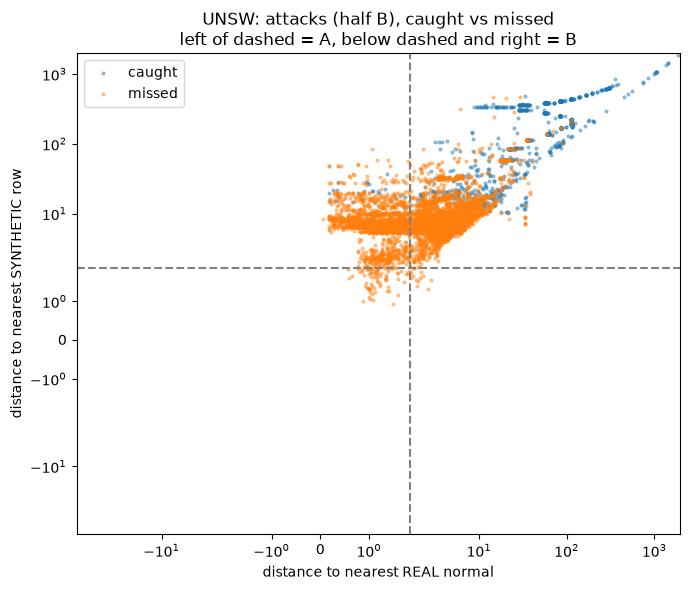

In [5]:
fig, ax = plt.subplots(figsize=(7, 6))
for b, m in [("neither", "caught"), ("missed", "missed")]:
    sel = attacks["missed_by"].eq("neither") if b == "neither" else attacks["missed_by"].ne("neither")
    ax.scatter(attacks.loc[sel, "d_real"], attacks.loc[sel, "d_syn"], s=4, alpha=0.4, label=m)
ax.axvline(r, c="grey", ls="--"); ax.axhline(r, c="grey", ls="--")
ax.set_xscale("symlog"); ax.set_yscale("symlog")
ax.set_xlabel("distance to nearest REAL normal"); ax.set_ylabel("distance to nearest SYNTHETIC row")
ax.set_title(f"{DATASET}: attacks (half B), caught vs missed\nleft of dashed = A, below dashed and right = B")
ax.legend(); plt.tight_layout(); plt.show()

---
**4. Where do the misses live? (categorical combo)**

For each combo we show attacks caught vs missed, plus how much of our synthetic data and of real normal data falls in that combo. If a combo has many misses and lots of synthetic rows, generating less there is a candidate fix. The price is false alarms on real normals in that combo.

In [6]:
key = lambda d: d[cat_cols].astype(str).agg("/".join, axis=1)
attacks["combo"] = key(attacks)
combo = pd.DataFrame({
    "attacks": attacks.groupby("combo").size(),
    "missed": attacks[attacks["missed_by"] != "neither"].groupby("combo").size(),
    "synth_share": key(synth).value_counts(normalize=True),
    "real_normal_share": key(normal_df).value_counts(normalize=True),
}).fillna(0)
combo["miss_rate"] = combo["missed"] / combo["attacks"].replace(0, np.nan)
combo["share_of_all_misses"] = combo["missed"] / combo["missed"].sum()
print(combo.sort_values("missed", ascending=False).head(12).round(3).to_string())

                  attacks  missed  synth_share  real_normal_share  miss_rate  share_of_all_misses
tcp/-/FIN          2804.0  2739.0        0.420              0.492      0.977                0.415
tcp/http/FIN       1874.0  1797.0        0.114              0.105      0.959                0.273
udp/-/INT           786.0   681.0        0.000              0.052      0.866                0.103
tcp/smtp/FIN        535.0   488.0        0.033              0.027      0.912                0.074
udp/dns/INT         733.0   223.0        0.000              0.000      0.304                0.034
tcp/ftp/FIN         245.0   212.0        0.021              0.023      0.865                0.032
tcp/pop3/FIN        172.0   145.0        0.000              0.000      0.843                0.022
tcp/ftp-data/FIN    113.0   107.0        0.054              0.042      0.947                0.016
unas/-/INT           39.0    39.0        0.000              0.000      1.000                0.006
udp/-/CON           

---
**5. Which columns hide the misses?**

For every numeric column: what fraction of **missed** attacks have a value inside the *central 90%* of the synthetic data (5th–95th percentile)? The same fraction is computed for **caught** attacks as a reference.

A column where nearly every missed attack sits in the synthetic central range, while caught attacks don't, is a column where the attacks blend in. ECOD scores each column separately, so these are the columns where ECOD can't see the misses.

In [7]:
lo, hi = synth[num_cols].quantile(0.05), synth[num_cols].quantile(0.95)
inside = lambda d: ((d[num_cols] >= lo) & (d[num_cols] <= hi)).mean()
cols = pd.DataFrame({
    "missed_inside": inside(attacks[attacks["missed_by"] != "neither"]),
    "caught_inside": inside(attacks[attacks["missed_by"] == "neither"]),
    "real_normal_inside": inside(normal_df),
})
cols["gap"] = cols["missed_inside"] - cols["caught_inside"]
print("Columns where missed attacks blend in most, relative to caught attacks:")
print(cols.sort_values("gap", ascending=False).head(15).round(3).to_string())

Columns where missed attacks blend in most, relative to caught attacks:
                  missed_inside  caught_inside  real_normal_inside    gap
dpkts                     0.824          0.171               0.862  0.653
ct_dst_src_ltm            0.982          0.351               0.964  0.631
ct_src_dport_ltm          0.984          0.358               0.941  0.626
dbytes                    0.808          0.220               0.811  0.589
ct_srv_dst                0.995          0.412               0.973  0.583
ct_srv_src                0.993          0.409               0.969  0.583
ct_dst_sport_ltm          0.946          0.386               0.969  0.559
ct_state_ttl              0.839          0.294               0.885  0.545
sbytes                    0.841          0.301               0.836  0.539
ct_dst_ltm                0.988          0.523               0.973  0.465
dload                     0.542          0.166               0.638  0.376
ct_src_ltm                0.969         

---
**6. Ceiling check: how much could fixing bucket B gain at best?**

Re-score with a hypothetical **perfect** fix: every bucket-B attack gets the highest score seen. Bucket A and C attacks are left unchanged. This is an optimistic upper bound for the "stop generating where real normals don't live" idea.

In [8]:
def S_with(boost_mask):
    se, si = s_ecod.copy(), s_if.copy()
    idx = np.where(is_a)[0][boost_mask]
    se[idx], si[idx] = se.max() + 1, si.max() + 1
    return (average_precision_score(y, se) + average_precision_score(y, si)) / 2

base = (ap_e + ap_i) / 2
for name in ["B. hidden by our synthetic", "C. far from both", "A. looks like real normal"]:
    m = (attacks["bucket"] == name).to_numpy() & (attacks["missed_by"] != "neither").to_numpy()
    print(f"perfectly fix missed '{name}' ({m.sum()} attacks): S {base:.4f} -> {S_with(m):.4f}")

perfectly fix missed 'B. hidden by our synthetic' (11 attacks): S 0.3834 -> 0.3862
perfectly fix missed 'C. far from both' (3562 attacks): S 0.3834 -> 0.7503
perfectly fix missed 'A. looks like real normal' (3021 attacks): S 0.3834 -> 0.7526


---
**7. Zoom in: does the connection type give bucket-C attacks away?**

Hypothesis: inside one connection type (categorical combo), bucket-C attacks *do* differ from that type's normal traffic in some column. They only look normal because **other** connection types' normal traffic covers the same values, and the guards check columns across all types mixed together.

For the combos with the most bucket-C misses, and for every numeric column:
- `out_within`: share of the combo's C attacks that fall **outside the 1st–99th percentile of real normals of the same combo**. This is what a guard would catch if it only compared against same-type normal traffic.
- `out_global`: the same, but against **all** real normals, roughly what the guards see today.
- `false_alarm`: share of the combo's own real normals outside that same-combo range, 2% by construction for a single column.

A big `out_within` with a small `out_global` means the column separates the attacks **within** the type, and the signal is being drowned out by other types.

In [9]:
attacks["missed"] = attacks["missed_by"] != "neither"
C = attacks[(attacks["bucket"] == "C. far from both") & attacks["missed"]]
normal_combo = key(normal_df)
top_combos = C["combo"].value_counts().head(4)
print("bucket-C misses per combo (top 4):")
print(top_combos.to_string(), "\n")

def outside(vals, ref, q=0.01):
    lo, hi = ref.quantile(q), ref.quantile(1 - q)
    return ((vals < lo) | (vals > hi)).mean()

per_col = []
for cb in top_combos.index:
    a, n = C[C["combo"] == cb], normal_df[normal_combo == cb]
    for col in num_cols:
        per_col.append(dict(combo=cb, column=col, n_C=len(a), n_normal=len(n),
                            out_within=outside(a[col], n[col]), out_global=outside(a[col], normal_df[col]),
                            false_alarm=outside(n[col], n[col])))
per_col = pd.DataFrame(per_col)
per_col["gain"] = per_col["out_within"] - per_col["out_global"]

for cb in top_combos.index:
    t = per_col[per_col["combo"] == cb].sort_values("out_within", ascending=False).head(8)
    print(f"=== {cb}: {t.n_C.iloc[0]} C-misses vs {t.n_normal.iloc[0]} same-combo normals ===")
    print(t[["column", "out_within", "out_global", "false_alarm", "gain"]].round(3).to_string(index=False), "\n")

bucket-C misses per combo (top 4):
combo
tcp/http/FIN    1182
tcp/-/FIN        906
tcp/smtp/FIN     484
udp/dns/INT      223 

=== tcp/http/FIN: 1182 C-misses vs 3661 same-combo normals ===
    column  out_within  out_global  false_alarm   gain
    sbytes       0.074       0.022        0.017  0.052
     smean       0.027       0.026        0.009  0.001
     dload       0.025       0.000        0.020  0.025
    ackdat       0.024       0.005        0.020  0.019
     stcpb       0.023       0.012        0.020  0.011
    tcprtt       0.021       0.002        0.020  0.019
ct_src_ltm       0.020       0.030        0.010 -0.009
    synack       0.017       0.003        0.020  0.014 

=== tcp/-/FIN: 906 C-misses vs 17212 same-combo normals ===
          column  out_within  out_global  false_alarm  gain
           smean       0.121       0.082        0.016 0.040
          sbytes       0.085       0.078        0.019 0.007
           sloss       0.058       0.039        0.014 0.020
           sl

**7b. Combined over all columns: how many C attacks would a "same-type" check catch, and at what cost?**

Flag a row if **any** column is outside the same-combo 1st–99th percentile range. Do this for the combo's C attacks (catch rate) and for the combo's real normals (false-alarm rate, which grows with the number of columns). Then repeat against all normals mixed together, for comparison.

In [10]:
summary = []
for cb in top_combos.index:
    a, n = C[C["combo"] == cb], normal_df[normal_combo == cb]
    lo_w, hi_w = n[num_cols].quantile(0.01), n[num_cols].quantile(0.99)
    lo_g, hi_g = normal_df[num_cols].quantile(0.01), normal_df[num_cols].quantile(0.99)
    any_out = lambda d, lo, hi: ((d[num_cols] < lo) | (d[num_cols] > hi)).any(axis=1).mean()
    summary.append(dict(combo=cb, C_misses=len(a),
                        catch_same_type=any_out(a, lo_w, hi_w), false_alarm_same_type=any_out(n, lo_w, hi_w),
                        catch_all_normals=any_out(a, lo_g, hi_g), false_alarm_all_normals=any_out(n, lo_g, hi_g)))
pd.DataFrame(summary).round(3)

,combo,C_misses,catch_same_type,false_alarm_same_type,catch_all_normals,false_alarm_all_normals
0,tcp/http/FIN,1182,0.227,0.196,0.267,0.235
1,tcp/-/FIN,906,0.428,0.192,0.253,0.106
2,tcp/smtp/FIN,484,1.000,0.148,0.262,0.023
3,udp/dns/INT,223,1.000,0.400,0.646,0.200


---
**Findings: UNSW, `synthetic_UNSW_clf0.01_holdout.csv` (S = 0.383), run 2026-10-03**

**1. The guards miss most attacks.** At the "no more suspicious than the 95th-percentile normal" cut-off, ECOD misses 85% of the half-B attacks and IForest misses 81%; 78% are missed by both.

**2. Bucket B is almost empty: 11 of 6,594 misses (0.2%).** Our VAE is *not* hiding attacks by generating in empty space. Perfectly fixing B would only move S from 0.383 to 0.386. Any "stop generating there" or tighter-filter idea is a dead end, which matches the earlier flat clf_threshold and weighting results.

**3. The misses split roughly half and half between A and C.**
- **A. looks like real normal (46%).** These attacks sit right on top of real normal traffic, so no normal-only dataset can fix them. They're mostly `tcp/-/FIN` and `tcp/http/FIN`, the two biggest normal combos.
- **C. far from both (54%).** These attacks are *unlike* every normal and synthetic row, yet the guards still score them low. This is a blind spot in how the guards score, not a problem with our data's realism. Perfectly fixing C alone would take S from 0.383 to **0.750**. That's about the top team's level.

**4. Why C attacks fool the guards.** Section 5 shows the missed attacks have *every individual column* inside the normal central range: `dpkts`, `dbytes`, `sbytes`, the `ct_*` connection counts, `ct_state_ttl`. Caught attacks mostly don't. ECOD scores each column on its own, and IForest cuts one column at a time, so an attack built from individually-normal values in an abnormal *combination* slips through both.

**Implication.** The lever for the remaining gap is to **reshape the per-column / axis-aligned view the guards get**, so that bucket-C combinations become rare in at least one column the guards look at. That might mean changing how values are distributed *within* each categorical combo, or making the clusters tighter so the gaps between them are emptier. Being more realistic, or pruning harder, won't move it.

---
**Findings, section 7: does the connection type give bucket-C attacks away?** (2026-10-03)

**Yes for some types (about 20% of C misses), no for the biggest ones (about 59%).**

- **`tcp/smtp/FIN` and `udp/dns/INT` (707 C misses): the TTL columns give them away completely within the type.**
  - smtp attacks have `sttl` 62 or 254, `dttl` 252 and `ct_state_ttl` 1.
  - smtp normals have `sttl` 31, `dttl` 29 and `ct_state_ttl` 0, 99.5% of the time.
  - Same-type check: 100% outside the normal range. All-normals check: 0%.
  - **Why the guards miss them:** 27% of *all* real normals have `sttl=254` (mostly `tcp/-/FIN` and `udp/-/INT`), so the guards, which check columns across every type mixed together, treat attack TTLs as normal.
- Across the whole dataset TTL is close to an attack fingerprint:
  - attacks: `sttl` ∈ {254: 72%, 62: 28%}
  - normals: `sttl` ∈ {31: 65%, 254: 27%, 62: 7%}
- **Our synthetic data already dropped TTL=254**, because the `clf_threshold=0.01` filter removed it. Its `sttl` is about 31 and `ct_state_ttl` is 0 for 96% of rows. That's very likely where the 0.447 → 0.489 Kaggle gain came from. The remaining cost: the 27% of real normals with TTL=254 now *also* look suspicious, so they crowd the top of the ranking alongside the attacks. That's why TTL-flagged attacks still count as "missed" at the 95th-percentile-of-normals cut-off.
- **`tcp/http/FIN` and `tcp/-/FIN` (2,088 C misses): no single column separates the attacks, even within the type.** The best column catches 12%. Checking any column at once catches 23–43% of attacks, but flags about 19% of the same type's normals. These are genuine *combination* anomalies, which column-by-column guards fundamentally struggle with.
- **Side finding: the VAE smears discrete columns.** `sttl` in the synthetic data takes values like 29, 30 and 32, which never occur in real data (real values: 31 / 62 / 254). The decoder treats few-valued integer columns as continuous. This widens each column's spread for ECOD and is a fixable modelling flaw.

**Next levers:**
1. Model few-valued integer columns (TTLs, `ct_state_ttl`, and so on) as categories in the decoder, so that values like 29/30/32 that never appear in real data aren't generated.
2. Among rows that share the attack TTL, find what separates the real normals from the attacks, to cut the false alarms.

---
**8. False alarms: real normal traffic that shares the attack fingerprint**

Section 7 showed TTL is nearly an attack fingerprint on UNSW, but 27% of real normals also have `sttl=254`. Our synthetic data has almost no `sttl=254`, because the filter removed it, so the guards now treat *every* `sttl=254` row as suspicious, including those real normals. This section asks:

- **8a.** Who sits at the top of the guards' suspicion ranking: attacks, or real normals with the fingerprint?
- **8b.** Ceiling: what would S be if those fingerprint-normals were ranked below every attack?
- **8c.** Is there a column where fingerprint-normals differ from fingerprint-attacks? If so, the synthetic data could teach the guards "254 *with X* is normal" and leave "254 *without X*" suspicious.

Set by `FOCUS_COL` / `FOCUS_VAL` in the code below. This is an analysis knob; the generation pipeline stays generic.

In [11]:
FOCUS = {"UNSW": ("sttl", 254), "NSL": None}[DATASET]
assert FOCUS is not None, "section 8 is only set up for UNSW"
FOCUS_COL, FOCUS_VAL = FOCUS
fp = (eval_df[FOCUS_COL] == FOCUS_VAL).to_numpy()   # rows carrying the fingerprint

# combined guard ranking: mean rank-percentile of the two guards (what S roughly rewards)
rank = (pd.Series(s_ecod).rank(pct=True) + pd.Series(s_if).rank(pct=True)).to_numpy() / 2
group = np.select([is_a, is_n & fp], ["attack", f"normal with {FOCUS_COL}={FOCUS_VAL}"], "normal, other")

print(f"eval rows: {is_a.sum()} attacks ({(is_a & fp).sum()} with {FOCUS_COL}={FOCUS_VAL}), "
      f"{(is_n & fp).sum()} normals with {FOCUS_COL}={FOCUS_VAL}, {(is_n & ~fp).sum()} other normals")
print(f"synthetic rows with {FOCUS_COL}={FOCUS_VAL}: {(synth[FOCUS_COL] == FOCUS_VAL).mean():.1%}\n")

order = np.argsort(-rank)
rows = []
for k in [1000, 2500, 5000, 7500, 10000, 15000]:
    top = pd.Series(group[order[:k]]).value_counts(normalize=True)
    rows.append({"top-k most suspicious": k, **top.round(3).to_dict()})
print("8a. composition of the guards' most-suspicious rows:")
pd.DataFrame(rows).fillna(0).set_index("top-k most suspicious")

eval rows: 7500 attacks (5329 with sttl=254), 9497 normals with sttl=254, 25503 other normals
synthetic rows with sttl=254: 0.1%

8a. composition of the guards' most-suspicious rows:


,attack,normal with sttl=254,"normal, other"
top-k most suspicious,,,
1000,0.572,0.371,0.057
2500,0.452,0.350,0.198
5000,0.387,0.360,0.253
7500,0.377,0.394,0.229
10000,0.369,0.404,0.227
15000,0.350,0.413,0.237


In [12]:
# 8b. ceiling: push fingerprint-normals to the very bottom of both guards' scores
def S_scores(se, si):
    return (average_precision_score(y, se) + average_precision_score(y, si)) / 2
se, si = s_ecod.copy(), s_if.copy()
m = is_n & fp
se[m], si[m] = se.min() - 1, si.min() - 1
print(f"8b. S now: {S_scores(s_ecod, s_if):.4f}")
print(f"    S if every {FOCUS_COL}={FOCUS_VAL} normal were ranked below all attacks: {S_scores(se, si):.4f}")

8b. S now: 0.3834
    S if every sttl=254 normal were ranked below all attacks: 0.6177


**8c. Fingerprint-normals vs fingerprint-attacks: which columns separate them?**

Only rows with `FOCUS_COL = FOCUS_VAL` are used. For every numeric column we report `separation = |2·AUROC − 1|`, where 0 = identical distributions and 1 = perfectly separable by a single threshold, plus the medians of both groups and of our synthetic data. Categorical combos are compared too.

In [13]:
from sklearn.metrics import roc_auc_score
fn = eval_df[is_n & fp]          # fingerprint normals
fa = eval_df[is_a & fp]          # fingerprint attacks
sep = []
for col in num_cols:
    if col == FOCUS_COL:
        continue
    v = np.r_[fn[col].to_numpy(), fa[col].to_numpy()]
    lab = np.r_[np.zeros(len(fn)), np.ones(len(fa))]
    auc = roc_auc_score(lab, v) if np.unique(v).size > 1 else 0.5
    sep.append(dict(column=col, separation=abs(2 * auc - 1),
                    attacks_higher=auc > 0.5,
                    median_fp_normal=fn[col].median(), median_fp_attack=fa[col].median(),
                    median_synth=synth[col].median()))
sep = pd.DataFrame(sep).sort_values("separation", ascending=False)
print(f"{len(fn)} fingerprint-normals vs {len(fa)} fingerprint-attacks")
sep.head(12).round(3)

9497 fingerprint-normals vs 5329 fingerprint-attacks


,column,separation,attacks_higher,median_fp_normal,median_fp_attack,median_synth
31,ct_dst_src_ltm,0.330,False,3.000,2.000,2.000
36,ct_srv_dst,0.257,False,4.000,2.000,4.000
26,ct_srv_src,0.212,False,4.000,3.000,4.000
20,synack,0.183,False,0.069,0.046,0.000
19,tcprtt,0.171,False,0.130,0.094,0.000
22,smean,0.161,True,61.000,84.000,79.000
34,ct_flw_http_mthd,0.147,True,0.000,0.000,0.000
24,trans_depth,0.147,True,0.000,0.000,0.000
21,ackdat,0.120,False,0.057,0.047,0.000
15,swin,0.119,False,255.000,255.000,254.000


In [14]:
cmp_combo = pd.DataFrame({
    "fp_normals": key(fn).value_counts(normalize=True),
    "fp_attacks": key(fa).value_counts(normalize=True),
}).fillna(0).sort_values("fp_normals", ascending=False)
print("categorical combos within the fingerprint group:")
cmp_combo.head(10).round(3)

categorical combos within the fingerprint group:


,fp_normals,fp_attacks
tcp/-/FIN,0.671,0.464
udp/-/INT,0.192,0.146
tcp/-/REQ,0.078,0.000
tcp/ftp/FIN,0.034,0.025
tcp/http/FIN,0.018,0.180
tcp/-/RST,0.003,0.000
igmp/-/INT,0.002,0.000
udp/-/REQ,0.001,0.001
tcp/ssh/RST,0.001,0.000
udp/radius/INT,0.000,0.000


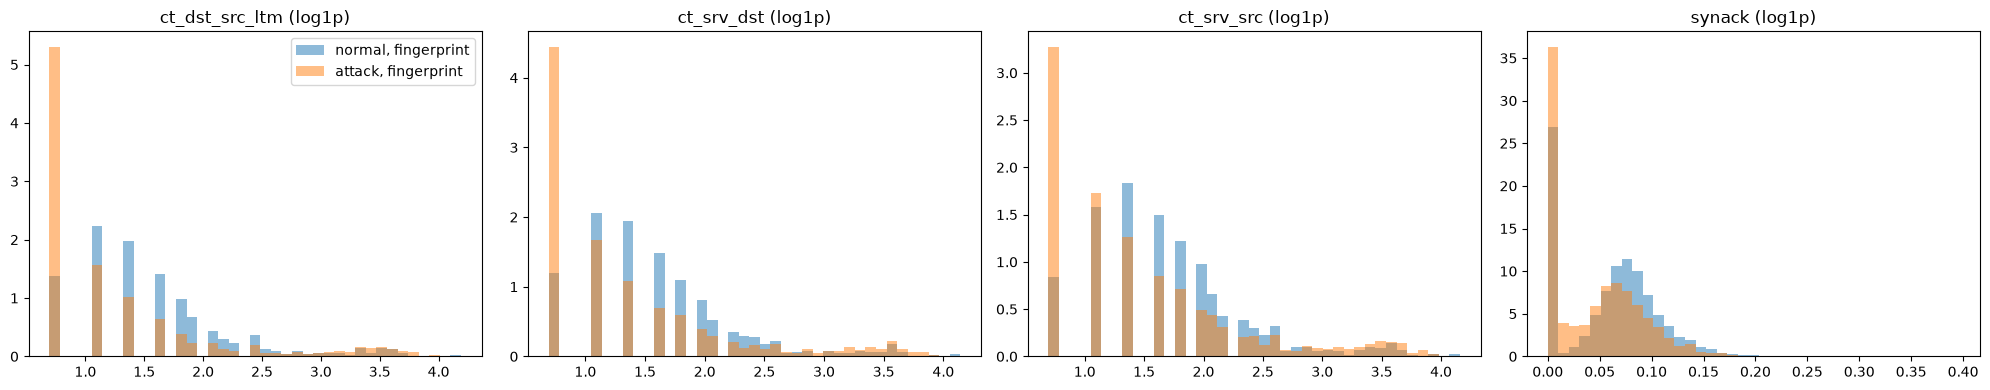

In [15]:
# the 4 best-separating columns: distributions of fingerprint-normals vs fingerprint-attacks
best = sep["column"].head(4).tolist()
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, best):
    lo, hi = np.log1p(eval_df.loc[fp, col].min()), np.log1p(eval_df.loc[fp, col].max())
    bins = np.linspace(lo, hi, 40)
    ax.hist(np.log1p(fn[col]), bins=bins, alpha=0.5, density=True, label="normal, fingerprint")
    ax.hist(np.log1p(fa[col]), bins=bins, alpha=0.5, density=True, label="attack, fingerprint")
    ax.set_title(f"{col} (log1p)")
axes[0].legend(); plt.tight_layout(); plt.show()

---
**Findings, section 8: false alarms from normals with `sttl=254`** (2026-10-03)

- **8a. The false alarms are real and large.** Among the guards' 7,500 most-suspicious rows, 38% are attacks and **39% are real normals with `sttl=254`**. Our synthetic data has only 0.1% `sttl=254` (the filter removed them), so the guards treat every 254 as suspicious, normal or not.
- **8b. The ceiling is high.** If every `sttl=254` normal were ranked below all attacks, S would go from 0.383 to **0.618**. This is the single biggest chunk of lost score we've found.
- **8c. But no single column separates 254-normals from 254-attacks well.** The best column is `ct_dst_src_ltm`, with separation 0.33 (0 = identical, 1 = perfect), followed by `ct_srv_dst` at 0.26 and `ct_srv_src` at 0.21. Normals have slightly *higher* connection counts (median 3–4 vs 2–3). Because the guards judge one column at a time, these weak differences don't give them much to work with.
- **The connection type helps a little:**
  - `tcp/-/REQ` is 7.8% of 254-normals and 0% of 254-attacks.
  - `tcp/http/FIN` is 1.8% of 254-normals and 18% of 254-attacks.
  - `tcp/-/FIN` (67% vs 46%) and `udp/-/INT` (19% vs 15%) are mixed.
- **Tension:** putting `sttl=254` rows back into the synthetic data would make 254-normals look familiar, but it would also make 254-attacks look familiar in the `sttl` column. The earlier `clf_threshold` sweep, where looser thresholds kept more 254 rows and scored lower, says bulk re-adding hurts. Any re-adding would have to be *selective*, limited to types where 254 is almost never an attack (for example `tcp/-/REQ`).